# NYC Yellow Taxi Demand and Fare Analysis

## Project Milestone 1

**Student:** Jonathan Niño Torres  
**Course:** BUS 612 – Data Wrangling and Visualization  
**Dataset Period:** January 2025  
**Data Source:** New York City Taxi and Limousine Commission

## Project Objective

The objective of this project is to analyze how yellow taxi demand in NYC varied by hour, day, and pickup location during January 2025. It will also examine the relationship between trip distance, trip duration, and total passenger charges. Finally, the project will identify which pickup and drop-off zones had the highest trip volumes and how their patterns varied by time and payment type. This analysis will focus exclusively on NYC Yellow Taxi trips.

## Dataset Description

The primary dataset was made available through the official New York City Taxi and Limousine Commission website, which is the source used for this project. It contains NYC Yellow Taxi trip records from January 2025.

Each row represents a single Yellow Taxi trip recorded in NYC during January 2025. The dataset includes variables related to pickup and drop-off dates and times, locations, passenger count, trip distance, payment type, and charges. These variables can be used to analyze taxi demand, travel patterns, and fare behavior. 

The Taxi Zone Lookup Table is a supporting dataset that contains borough and taxi zone names. It will be connected to the primary dataset by matching LocationID with PULocationID and DOLocationID. This will allow the project to identify where each trip starts and ends.

## Dataset Requirements

| Requirement | Evidence in the Selected Data |
|---|---|
| Time data | `tpep_pickup_datetime` and `tpep_dropoff_datetime` record when each trip begins and ends. |
| String data | `Borough`, `Zone`, and `service_zone` contain text describing the taxi locations. |
| Geolocation information | `PULocationID` and `DOLocationID` identify the pickup and drop-off taxi zones. |
| Numerical values | `passenger_count`, `trip_distance`, `fare_amount`, `tip_amount`, and `total_amount` contain numerical measurements for each trip. |
| Categorical values | `payment_type`, `RatecodeID`, and `VendorID` classify trips into categories such as payment method, rate type, and technology provider. |
| Hundreds or thousands of rows | The dataset contains 3,475,226 trip records, exceeding the minimum size requirement. |
| Around 10 columns | The dataset contains 20 columns, providing more than the approximately 10 required variables. |

In [1]:
import pandas as pd

taxi = pd.read_parquet("yellow_tripdata_2025-01.parquet")
taxi.shape

(3475226, 20)

## Research Questions

1. How does taxi demand vary by hour, day, and pickup zone during January 2025?

2. How are trip distance, trip duration, and total passenger charges related for NYC Yellow Taxi trips during January 2025?

3. Which pickup and drop-off zones have the highest trip volumes, and how does the distribution of payment types vary across those zones?


## Data Sources

- [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page)
- [January 2025 Yellow Taxi Trip Records (Parquet)](https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-01.parquet)
- [Taxi Zone Lookup Table (CSV)](https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv)
- [Yellow Taxi Trip Records Data Dictionary (PDF)](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

## Project Milestone 2

### 1. Number of Records

In [2]:
taxi.shape

(3475226, 20)

The primary dataset contains 3,475,226 records. Each record represents an individual NYC Yellow Taxi trip during January 2025.

### 2. Columns, Meanings, and Data Types

In [3]:
taxi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3475226 entries, 0 to 3475225
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

The dataset contains 20 columns: 2 datetime columns, 13 floating-point columns, 4 integer columns, and 1 object column.

#### Column Meanings

| Column | Meaning |
|---|---|
| `VendorID` | Identifies the TPEP technology provider that submitted the trip record. |
| `tpep_pickup_datetime` | Records the date and time when the trip started. |
| `tpep_dropoff_datetime` | Records the date and time when the trip ended. |
| `passenger_count` | Records the number of passengers reported by the driver. |
| `trip_distance` | Records the trip distance in miles reported by the taximeter. |
| `RatecodeID` | Indicates the final rate code in effect at the end of the trip.|
| `store_and_fwd_flag` | Indicates whether the trip record was temporarily stored because there was no connection to the server. |
| `PULocationID` | Records the TLC Taxi Zone in which the taximeter was engaged. |
| `DOLocationID` | Records the TLC Taxi Zone in which the taximeter was disengaged|
| `payment_type` | Records a numeric code signifying how the passenger paid for the trip.|
| `fare_amount` | Records the time-and-distance fare calculated by the taximeter. |
| `extra` | Records miscellaneous extra charges and surcharges applied to the trip. |
| `mta_tax` | Records the MTA tax automatically charged based on the metered rate. |
| `tip_amount` | Records the tip amount for credit card payments; cash tips are not included. |
| `tolls_amount` | Records the total amount of tolls paid during the trip. |
| `improvement_surcharge` | Records the improvement surcharge applied to the trip. |
| `total_amount` | Records the total amount charged to the passenger, excluding cash tips. |
| `congestion_surcharge` | Records the NYS congestion surcharge collected for the trip. |
| `Airport_fee` | Records the pickup fee applied at LaGuardia and JFK airports. |
| `cbd_congestion_fee` | Records the MTA congestion fee applied to trips involving the Congestion Relief Zone beginning January 5, 2025. |

### 3. Numerical Statistical Summary

In [4]:
quantitative_columns = [
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
    "cbd_congestion_fee"
]

quantitative_summary = taxi[quantitative_columns].describe().T
quantitative_summary["range"] = (
    quantitative_summary["max"] - quantitative_summary["min"]
)

quantitative_summary.round(2)


,count,mean,std,min,25%,50%,75%,max,range
passenger_count,2935077.0,1.30,0.75,0.00,1.00,1.00,1.00,9.00,9.00
trip_distance,3475226.0,5.86,564.60,0.00,0.98,1.67,3.10,276423.57,276423.57
fare_amount,3475226.0,17.08,463.47,-900.00,8.60,12.11,19.50,863372.12,864272.12
extra,3475226.0,1.32,1.86,-7.50,0.00,0.00,2.50,15.00,22.50
mta_tax,3475226.0,0.48,0.14,-0.50,0.50,0.50,0.50,10.50,11.00
tip_amount,3475226.0,2.96,3.78,-86.00,0.00,2.45,3.93,400.00,486.00
tolls_amount,3475226.0,0.45,2.00,-126.94,0.00,0.00,0.00,170.94,297.88
improvement_surcharge,3475226.0,0.95,0.28,-1.00,1.00,1.00,1.00,1.00,2.00
total_amount,3475226.0,25.61,463.66,-901.00,15.20,19.95,27.78,863380.37,864281.37
congestion_surcharge,2935077.0,2.23,0.90,-2.50,2.50,2.50,2.50,2.50,5.00


The median trip distance was 1.67 miles, while the mean was 5.86 miles. The summary also shows some values that may require further investigation, such as a maximum trip distance of 276,423.57 miles and a minimum total amount of -$901.00. These extreme values may represent outliers, corrections, or invalid records and should be examined before further analysis.

### 4. Categorical Column Frequencies

In [5]:
taxi["payment_type"].value_counts(dropna=False)

payment_type
1    2444393
0     540149
2     390429
4      76481
3      23773
5          1
Name: count, dtype: int64

In [6]:
payment_type_labels = {
    0: "Flex Fare trip",
    1: "Credit card",
    2: "Cash",
    3: "No charge",
    4: "Dispute",
    5: "Unknown",
    6: "Voided trip"
}

payment_type_summary = (
    taxi["payment_type"]
    .map(payment_type_labels)
    .value_counts(dropna=False)
    .rename_axis("payment_method")
    .reset_index(name="frequency")
)

payment_type_summary["percentage"] = (
    payment_type_summary["frequency"] / len(taxi) * 100
).round(2)

payment_type_summary

,payment_method,frequency,percentage
0,Credit card,2444393,70.34
1,Flex Fare trip,540149,15.54
2,Cash,390429,11.23
3,Dispute,76481,2.20
4,No charge,23773,0.68
5,Unknown,1,0.00


Credit card was the most common payment method, accounting for 70.34% of all trips. In comparison, cash accounted for 11.23% of trips, while Flex Fare trips represented 15.54%.

In [7]:
def categorical_summary(column, labels):
    labeled_values = taxi[column].map(labels)
    labeled_values = labeled_values.mask(taxi[column].isna(), "Missing")
    labeled_values = labeled_values.fillna("Unmapped code")

    summary = (
        labeled_values
        .value_counts(dropna=False)
        .rename_axis("category")
        .reset_index(name="frequency")
    )

    summary["percentage"] = (
        summary["frequency"] / len(taxi) * 100
    ).round(2)

    return summary

In [8]:
vendor_labels = {
    1: "Creative Mobile Technologies",
    2: "Curb Mobility",
    6: "Myle Technologies",
    7: "Helix"
}

ratecode_labels = {
    1: "Standard rate",
    2: "JFK",
    3: "Newark",
    4: "Nassau or Westchester",
    5: "Negotiated fare",
    6: "Group ride",
    99: "Null or unknown"
}

store_forward_labels = {
    "Y": "Store and forward",
    "N": "Not store and forward"
}

print("VendorID")
display(categorical_summary("VendorID", vendor_labels))

print("RatecodeID")
display(categorical_summary("RatecodeID", ratecode_labels))

print("Store and Forward Flag")
display(categorical_summary("store_and_fwd_flag", store_forward_labels))

VendorID


,category,frequency,percentage
0,Curb Mobility,2719860,78.26
1,Creative Mobile Technologies,753671,21.69
2,Helix,1206,0.03
3,Myle Technologies,489,0.01


RatecodeID


,category,frequency,percentage
0,Standard rate,2756472,79.32
1,Missing,540149,15.54
2,JFK,94420,2.72
3,Null or unknown,41963,1.21
4,Negotiated fare,26501,0.76
5,Newark,8622,0.25
6,Nassau or Westchester,7092,0.20
7,Group ride,7,0.00


Store and Forward Flag


,category,frequency,percentage
0,Not store and forward,2927431,84.24
1,Missing,540149,15.54
2,Store and forward,7646,0.22


Curb Mobility submitted 78.26% of the trip records, while Creative Mobile Technologies submitted 21.69%. The standard rate was the most common rate category, representing 79.32% of all trips. Only 0.22% of the records were classified as store-and-forward trips.

Interestingly, `RatecodeID` and `store_and_fwd_flag` each contained 540,149 missing values, or 15.54% of the dataset. This count is equal to the number of Flex Fare trips, suggesting a possible relationship that will be investigated during the missing-value analysis.

### 5. Time Range 

In [9]:
taxi[
    ["tpep_pickup_datetime", "tpep_dropoff_datetime"]
].agg(["min", "max"])

,tpep_pickup_datetime,tpep_dropoff_datetime
min,2024-12-31 20:47:55,2024-12-18 07:52:40
max,2025-02-01 00:00:44,2025-02-01 23:44:11


In [10]:
period_start = pd.Timestamp("2025-01-01")
period_end = pd.Timestamp("2025-02-01")

time_checks = pd.Series({
    "Pickups before January 2025":
        (taxi["tpep_pickup_datetime"] < period_start).sum(),

    "Pickups on or after February 2025":
        (taxi["tpep_pickup_datetime"] >= period_end).sum(),

    "Drop-offs before January 2025":
        (taxi["tpep_dropoff_datetime"] < period_start).sum(),

    "Drop-offs on or after February 2025":
        (taxi["tpep_dropoff_datetime"] >= period_end).sum(),

    "Drop-offs before pickup":
        (
            taxi["tpep_dropoff_datetime"]
            < taxi["tpep_pickup_datetime"]
        ).sum()
})

time_checks

Pickups before January 2025              21
Pickups on or after February 2025         1
Drop-offs before January 2025            14
Drop-offs on or after February 2025    1797
Drop-offs before pickup                 124
dtype: int64

The raw pickup timestamps range from December 31, 2024, to February 1, 2025, while the drop-off timestamps range from December 18, 2024, to February 1, 2025. The dataset contains 21 pickups before January and one pickup on or after February 1. It also contains 1,797 drop-offs on or after February 1, although some may correspond to trips that began late on January 31.

In addition, 124 records have a drop-off time earlier than their pickup time. These records will require additional validation and will not be used for duration-based analysis unless their timestamps can be corrected. Future analyses will define January trips using pickup times from January 1, inclusive, through February 1, exclusive.

### 6. Geolocation Frequencies

In [11]:
zones = pd.read_csv("taxi_zone_lookup.csv")
zones.head()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [12]:
pickup_frequency = (
    taxi["PULocationID"]
    .value_counts()
    .rename_axis("LocationID")
    .reset_index(name="pickup_count")
    .merge(
        zones[["LocationID", "Borough", "Zone"]],
        on="LocationID",
        how="left"
    )
    .sort_values("pickup_count", ascending=False)
)

pickup_frequency["percentage"] = (
    pickup_frequency["pickup_count"] / len(taxi) * 100
).round(2)

pickup_frequency.head(10)

,LocationID,pickup_count,Borough,Zone,percentage
0,161,169977,Manhattan,Midtown Center,4.89
1,237,163703,Manhattan,Upper East Side South,4.71
2,236,155647,Manhattan,Upper East Side North,4.48
3,132,146137,Queens,JFK Airport,4.21
4,230,125829,Manhattan,Times Sq/Theatre District,3.62
5,186,119131,Manhattan,Penn Station/Madison Sq West,3.43
6,162,117930,Manhattan,Midtown East,3.39
7,142,110585,Manhattan,Lincoln Square East,3.18
8,239,96614,Manhattan,Upper West Side South,2.78
9,163,95906,Manhattan,Midtown North,2.76


In [13]:
dropoff_frequency = (
    taxi["DOLocationID"]
    .value_counts()
    .rename_axis("LocationID")
    .reset_index(name="dropoff_count")
    .merge(
        zones[["LocationID", "Borough", "Zone"]],
        on="LocationID",
        how="left"
    )
    .sort_values("dropoff_count", ascending=False)
)

dropoff_frequency["percentage"] = (
    dropoff_frequency["dropoff_count"] / len(taxi) * 100
).round(2)

dropoff_frequency.head(10)

,LocationID,dropoff_count,Borough,Zone,percentage
0,236,161376,Manhattan,Upper East Side North,4.64
1,237,149970,Manhattan,Upper East Side South,4.32
2,161,131258,Manhattan,Midtown Center,3.78
3,230,108177,Manhattan,Times Sq/Theatre District,3.11
4,170,100060,Manhattan,Murray Hill,2.88
5,142,98982,Manhattan,Lincoln Square East,2.85
6,239,97559,Manhattan,Upper West Side South,2.81
7,162,93798,Manhattan,Midtown East,2.70
8,141,92675,Manhattan,Lenox Hill West,2.67
9,68,89232,Manhattan,East Chelsea,2.57


Midtown Center had the highest pickup frequency, with 169,977 trips, representing 4.89% of all records. Upper East Side North had the highest drop-off frequency, with 161,376 trips, or 4.64% of the dataset.

Nine of the ten most frequent pickup zones were located in Manhattan, with JFK Airport as the only exception. All ten of the most frequent drop-off zones were located in Manhattan. These results demonstrate that Yellow Taxi activity was highly concentrated in Manhattan, while JFK Airport was also an important trip origin.

### 7. Data Type Conversions

In [14]:
(
    taxi["passenger_count"]
    .dropna()
    .mod(1)
    .ne(0)
    .sum()
)

np.int64(0)

In [15]:
conversion_columns = [
    "passenger_count",
    "VendorID",
    "RatecodeID",
    "store_and_fwd_flag",
    "payment_type"
]

types_before = taxi[conversion_columns].dtypes.astype(str)

taxi["passenger_count"] = taxi["passenger_count"].astype("Int64")

categorical_columns = [
    "VendorID",
    "RatecodeID",
    "store_and_fwd_flag",
    "payment_type"
]

for column in categorical_columns:
    taxi[column] = taxi[column].astype("category")

type_comparison = pd.DataFrame({
    "before": types_before,
    "after": taxi[conversion_columns].dtypes.astype(str)
})

type_comparison

,before,after
passenger_count,float64,Int64
VendorID,int32,category
RatecodeID,float64,category
store_and_fwd_flag,object,category
payment_type,int64,category


`passenger_count` was originally stored as `float64` because the column contains missing values. After confirming that all non-missing observations were whole numbers, it was converted to the nullable `Int64` type.

`VendorID`, `RatecodeID`, `store_and_fwd_flag`, and `payment_type` were converted to the `category` data type because they represent classifications rather than numerical measurements. `PULocationID` and `DOLocationID` remain integers because they are used as keys to connect the trip records with the Taxi Zone Lookup Table.

### 8. Missing Values and Treatment Strategy

In [16]:
missing_summary = pd.DataFrame({
    "missing_count": taxi.isna().sum(),
    "missing_percentage": (taxi.isna().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[
        missing_summary["missing_count"] > 0
    ]
    .sort_values("missing_count", ascending=False)
)

missing_summary

,missing_count,missing_percentage
passenger_count,540149,15.54
RatecodeID,540149,15.54
store_and_fwd_flag,540149,15.54
congestion_surcharge,540149,15.54
Airport_fee,540149,15.54


In [17]:
missing_columns = [
    "passenger_count",
    "RatecodeID",
    "store_and_fwd_flag",
    "congestion_surcharge",
    "Airport_fee"
]

all_five_missing = taxi[missing_columns].isna().all(axis=1)
any_missing = taxi[missing_columns].isna().any(axis=1)
flex_fare = taxi["payment_type"] == 0

missing_pattern_check = pd.Series({
    "Rows with all five values missing": all_five_missing.sum(),
    "Rows with any of the five values missing": any_missing.sum(),
    "Flex Fare trips": flex_fare.sum(),
    "Flex Fare trips with all five values missing":
        (flex_fare & all_five_missing).sum()
})

missing_pattern_check

Rows with all five values missing               540149
Rows with any of the five values missing        540149
Flex Fare trips                                 540149
Flex Fare trips with all five values missing    540149
dtype: int64

Five columns contain 540,149 missing values each, representing 15.54% of the dataset. The missing values occur together in the same records, and all these records correspond to Flex Fare trips. Therefore, the missingness is systematic rather than random.

These trips will be retained for demand and geolocation analyses because removing them would discard 15.54% of the dataset. Missing numerical values will not be replaced with zero because missing does not necessarily mean zero. Analyses requiring these variables will use the available observations for each specific variable.

### 9. Correlation Between Numerical Variables

In [18]:
taxi["trip_duration_minutes"] = (
    taxi["tpep_dropoff_datetime"] - taxi["tpep_pickup_datetime"]
).dt.total_seconds() / 60

taxi[
    ["trip_distance", "trip_duration_minutes", "total_amount"]
].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
trip_distance,3475226.0,5.86,564.60,0.00,0.98,1.67,3.10,276423.57
trip_duration_minutes,3475226.0,15.02,38.71,-51472.32,7.28,11.70,18.33,5626.32
total_amount,3475226.0,25.61,463.66,-901.00,15.20,19.95,27.78,863380.37


In [19]:
correlation_columns = [
    "trip_distance",
    "trip_duration_minutes",
    "total_amount"
]

correlation_data = taxi[correlation_columns].dropna().copy()

# Keep only positive values
correlation_data = correlation_data[
    (correlation_data > 0).all(axis=1)
]

# Identify the 99th percentile of each variable
upper_limits = correlation_data.quantile(0.99)

# Remove extreme values above those limits
correlation_data = correlation_data[
    correlation_data.le(upper_limits).all(axis=1)
]

print("99th percentile limits:")
display(upper_limits.round(2))

print("Records retained for correlation:")
print(f"{len(correlation_data):,}")

99th percentile limits:


trip_distance             19.53
trip_duration_minutes     59.07
total_amount             102.41
Name: 0.99, dtype: float64

Records retained for correlation:
3,248,074


In [20]:
correlation_matrix = correlation_data.corr().round(3)
correlation_matrix

,trip_distance,trip_duration_minutes,total_amount
trip_distance,1.000,0.789,0.902
trip_duration_minutes,0.789,1.000,0.790
total_amount,0.902,0.790,1.000


To reduce the influence of invalid and extreme values, the correlation analysis included only positive observations at or below the 99th percentile for trip distance, trip duration, and total amount. This retained 3,248,074 records.

The strongest positive correlation was between trip distance and total amount (r = 0.902). This indicates that as trip distance increases, the total amount charged also tends to increase. In practical terms, longer taxi trips generally cost more.

### 10. Three Interesting Facts About the Dataset

1. Credit cards represented 70.34% of all trips, compared with 11.23% paid in cash. This suggests that NYC Yellow Taxi passengers preferred credit cards over cash.
2. Yellow Taxi activity was highly concentrated in Manhattan. Nine of the ten busiest pickup zones and all ten busiest drop-off zones were located in Manhattan.
3. Curb Mobility submitted 78.26% of the trip records, while Creative Mobile Technologies submitted 21.69%.

## Project Milestone 3

### 1. Taxi Demand Pivot Table

In [21]:
january_mask = (
    (taxi["tpep_pickup_datetime"] >= "2025-01-01") &
    (taxi["tpep_pickup_datetime"] < "2025-02-01")
)

taxi_m3 = taxi.loc[
    january_mask,
    [
        "tpep_pickup_datetime",
        "PULocationID",
        "DOLocationID",
        "payment_type",
        "trip_distance",
        "trip_duration_minutes",
        "total_amount"
    ]
].copy()

taxi_m3["pickup_day"] = taxi_m3["tpep_pickup_datetime"].dt.day_name()
taxi_m3["pickup_hour"] = taxi_m3["tpep_pickup_datetime"].dt.hour

taxi_m3.shape

(3475204, 9)

In [22]:
day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

taxi_m3["pickup_day"] = pd.Categorical(
    taxi_m3["pickup_day"],
    categories=day_order,
    ordered=True
)

In [23]:
demand_pivot = taxi_m3.pivot_table(
    index="pickup_day",
    columns="pickup_hour",
    values="PULocationID",
    aggfunc="count",
    fill_value=0,
    observed=False
)

demand_pivot

pickup_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
pickup_day,,,,,,,,,,,,,,,,,,,,,
Monday,7422,3847,2227,1583,1836,3093,6980,13762,18327,17367,...,22955,24614,24094,26971,27201,21728,19567,19508,14136,9066
Tuesday,4628,1921,1032,755,1111,2883,7926,18126,25419,23592,...,25979,28075,28725,35265,37632,28540,28461,31929,21947,11206
Wednesday,12248,10421,8299,5752,4040,4315,9281,20073,27479,25453,...,31753,34436,34445,42629,45087,36731,34751,38020,29943,15002
Thursday,7174,3127,1769,1301,1647,3764,9961,21420,29855,28284,...,34346,36691,38132,48583,53085,41735,38087,40830,36076,23100
Friday,11552,5783,3174,2227,2231,4214,9038,19055,24383,23239,...,34110,36365,36291,44395,48563,40847,31400,31956,35005,34612
Saturday,23169,17785,12301,7405,3918,1945,3318,5036,8145,13013,...,26892,28858,30819,30860,31596,31043,23960,25653,29023,32493
Sunday,27223,21600,15127,9469,5250,2337,3522,5109,7697,11929,...,26254,24655,24545,24815,24787,20431,18772,18079,16084,11318


In [24]:
taxi_m3["pickup_date"] = taxi_m3["tpep_pickup_datetime"].dt.date

day_occurrences = (
    taxi_m3.groupby("pickup_day", observed=False)["pickup_date"]
    .nunique()
)

average_demand_pivot = (
    demand_pivot
    .div(day_occurrences, axis=0)
    .round(0)
    .astype(int)
)

average_demand_pivot

pickup_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
pickup_day,,,,,,,,,,,,,,,,,,,,,
Monday,1856,962,557,396,459,773,1745,3440,4582,4342,...,5739,6154,6024,6743,6800,5432,4892,4877,3534,2266
Tuesday,1157,480,258,189,278,721,1982,4532,6355,5898,...,6495,7019,7181,8816,9408,7135,7115,7982,5487,2802
Wednesday,2450,2084,1660,1150,808,863,1856,4015,5496,5091,...,6351,6887,6889,8526,9017,7346,6950,7604,5989,3000
Thursday,1435,625,354,260,329,753,1992,4284,5971,5657,...,6869,7338,7626,9717,10617,8347,7617,8166,7215,4620
Friday,2310,1157,635,445,446,843,1808,3811,4877,4648,...,6822,7273,7258,8879,9713,8169,6280,6391,7001,6922
Saturday,5792,4446,3075,1851,980,486,830,1259,2036,3253,...,6723,7214,7705,7715,7899,7761,5990,6413,7256,8123
Sunday,6806,5400,3782,2367,1312,584,880,1277,1924,2982,...,6564,6164,6136,6204,6197,5108,4693,4520,4021,2830


In [25]:
peak_day, peak_hour = average_demand_pivot.stack().idxmax()
peak_pickups = average_demand_pivot.stack().max()

print("Peak day:", peak_day)
print("Peak hour:", peak_hour)
print("Average pickups:", peak_pickups)

Peak day: Thursday
Peak hour: 18
Average pickups: 10617


After adjusting for the number of times each weekday occurred in January 2025, the results show that the busiest period for NYC Yellow Taxis was Thursday between 6:00 p.m. and 7:00 p.m., with an average of 10,617 pickups. This finding is consistent with the evening rush hour, when many people are commuting home from work. The results also show high weekend demand, particularly during nighttime and early-morning hours.

### 2. Index and MultiIndex Analysis

In [26]:
zone_indexed = pickup_frequency.set_index("LocationID")

zone_indexed.head()

,pickup_count,Borough,Zone,percentage
LocationID,,,,
161,169977,Manhattan,Midtown Center,4.89
237,163703,Manhattan,Upper East Side South,4.71
236,155647,Manhattan,Upper East Side North,4.48
132,146137,Queens,JFK Airport,4.21
230,125829,Manhattan,Times Sq/Theatre District,3.62


In [27]:
zone_indexed.loc[161]

pickup_count            169977
Borough              Manhattan
Zone            Midtown Center
percentage                4.89
Name: 161, dtype: object

In [28]:
zone_multi_indexed = (
    pickup_frequency
    .set_index(["Borough", "Zone"])
    .sort_index()
)

zone_multi_indexed.head()

LocationID  pickup_count  percentage
Borough Zone                                                         
Bronx   Allerton/Pelham Gardens           3           175        0.01
        Bedford Park                     18           344        0.01
        Belmont                          20           199        0.01
        Bronx Park                       31            37        0.00
        Bronxdale                        32           220        0.01

In [29]:
manhattan_zones = (
    zone_multi_indexed
    .loc["Manhattan"]
    .sort_values("pickup_count", ascending=False)
    .head(10)
)

manhattan_zones

,LocationID,pickup_count,percentage
Zone,,,
Midtown Center,161,169977,4.89
Upper East Side South,237,163703,4.71
Upper East Side North,236,155647,4.48
Times Sq/Theatre District,230,125829,3.62
Penn Station/Madison Sq West,186,119131,3.43
Midtown East,162,117930,3.39
Lincoln Square East,142,110585,3.18
Upper West Side South,239,96614,2.78
Midtown North,163,95906,2.76


Using the MultiIndex, the analysis isolated Manhattan and ranked its pickup zones by demand. Midtown Center had the highest number of pickups, with 169,977 trips, followed by Upper East Side South with 163,703 and Upper East Side North with 155,647. This demonstrates how hierarchical indexing can support targeted analysis within a specific borough.

### 3. GroupBy Analysis

In [30]:
payment_groupby = (
    taxi_m3
    .groupby("payment_type", observed=False)
    .agg(
        trip_count=("PULocationID", "count")
    )
)

payment_groupby

,trip_count
payment_type,
0,540149
1,2444377
2,390423
3,23773
4,76481
5,1


In [31]:
payment_groupby = (
    taxi_m3
    .groupby("payment_type", observed=False)
    .agg(
        trip_count=("PULocationID", "count"),
        median_distance=("trip_distance", "median"),
        median_duration=("trip_duration_minutes", "median"),
        median_total=("total_amount", "median")
    )
    .round(2)
)

payment_groupby

,trip_count,median_distance,median_duration,median_total
payment_type,,,,
0,540149,2.04,13.78,18.81
1,2444377,1.63,11.37,21.00
2,390423,1.50,10.83,16.80
3,23773,0.89,6.90,9.40
4,76481,1.41,10.22,5.50
5,1,0.00,0.32,0.00


In [32]:
payment_labels = {
    0: "Flex Fare",
    1: "Credit card",
    2: "Cash",
    3: "No charge",
    4: "Dispute",
    5: "Unknown"
}

payment_groupby = payment_groupby.rename(index=payment_labels)
payment_groupby

,trip_count,median_distance,median_duration,median_total
payment_type,,,,
Flex Fare,540149,2.04,13.78,18.81
Credit card,2444377,1.63,11.37,21.00
Cash,390423,1.50,10.83,16.80
No charge,23773,0.89,6.90,9.40
Dispute,76481,1.41,10.22,5.50
Unknown,1,0.00,0.32,0.00


The GroupBy analysis shows that credit cards were the most frequently used payment method, accounting for 2,444,377 trips. Flex Fare was the second most common payment category, with 540,149 trips, exceeding the 390,423 trips paid in cash. Flex Fare trips also had the longest median distance and duration, at 2.04 miles and 13.78 minutes, respectively

### 4. Wide-to-Long Format Conversion

In [33]:
demand_long = (
    average_demand_pivot
    .reset_index()
    .melt(
        id_vars="pickup_day",
        var_name="pickup_hour",
        value_name="average_pickups"
    )
)

demand_long.head(10)

,pickup_day,pickup_hour,average_pickups
0,Monday,0,1856
1,Tuesday,0,1157
2,Wednesday,0,2450
3,Thursday,0,1435
4,Friday,0,2310
5,Saturday,0,5792
6,Sunday,0,6806
7,Monday,1,962
8,Tuesday,1,480
9,Wednesday,1,2084


In [34]:
print("Wide shape:", average_demand_pivot.shape)
print("Long shape:", demand_long.shape)

Wide shape: (7, 24)
Long shape: (168, 3)


The original wide-format table contained one row for each weekday and one column for each hour. Using melt(), it was converted into a long-format table with 168 rows and three variables: pickup_day, pickup_hour, and average_pickups. Long format is more suitable for filtering, grouping, and visualization.

### 5. String-Based Analysis

In [35]:
airport_zones = (
    pickup_frequency[
        pickup_frequency["Zone"].str.contains(
            "Airport",
            case=False,
            na=False
        )
    ][["Borough", "Zone", "pickup_count", "percentage"]]
    .sort_values("pickup_count", ascending=False)
)

airport_zones

,Borough,Zone,pickup_count,percentage
3,Queens,JFK Airport,146137,4.21
13,Queens,LaGuardia Airport,89658,2.58
156,EWR,Newark Airport,377,0.01


The string-based analysis identified three pickup zones containing the word “Airport.” JFK Airport had the highest demand, with 146,137 pickups (4.21% of all trips), followed by LaGuardia Airport with 89,658 pickups (2.58%). Newark Airport recorded only 377 pickups (0.01%), which is reasonable because it is located outside New York City.

### 6. Three Interesting Facts

1. The busiest period of the week for NYC Yellow Taxis was Thursday between 6:00 p.m. and 7:00 p.m., with an average of 10,617 pickups.

2. Credit cards were the most frequently used payment method among NYC Yellow Taxi passengers, accounting for 2,444,377 trips.

3. JFK Airport was the busiest airport pickup zone for NYC Yellow Taxis in January 2025, recording 146,137 pickups—more than LaGuardia and Newark airports.

## Project Milestone 4: Data Visualization

### 1. Average Taxi Demand by Day and Hour

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

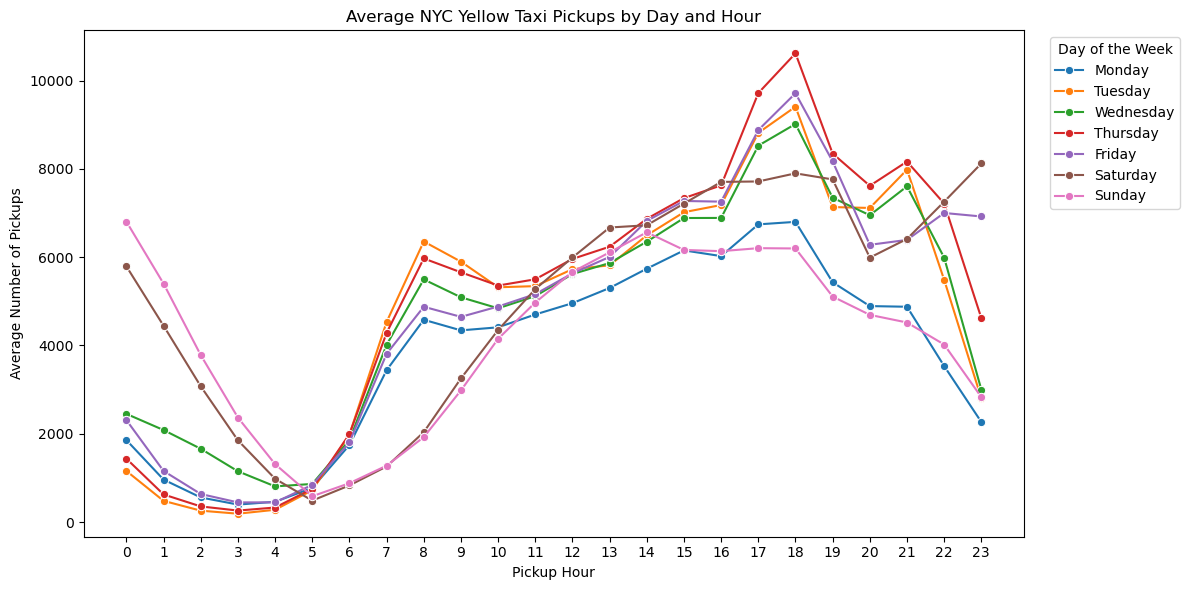

In [37]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=demand_long,
    x="pickup_hour",
    y="average_pickups",
    hue="pickup_day",
    marker="o"
)

plt.title("Average NYC Yellow Taxi Pickups by Day and Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Average Number of Pickups")
plt.xticks(range(0, 24))
plt.legend(
    title="Day of the Week",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

This line chart compares the average number of NYC Yellow Taxi pickups across days of the week and hours of the day. Each colored line represents one day of the week. The results show that the highest average demand occurred on Thursday at 6:00 p.m., with 10,617 pickups. Weekend demand was particularly high during late-night and early-morning hours.

### 2. Airport Pickup Comparison

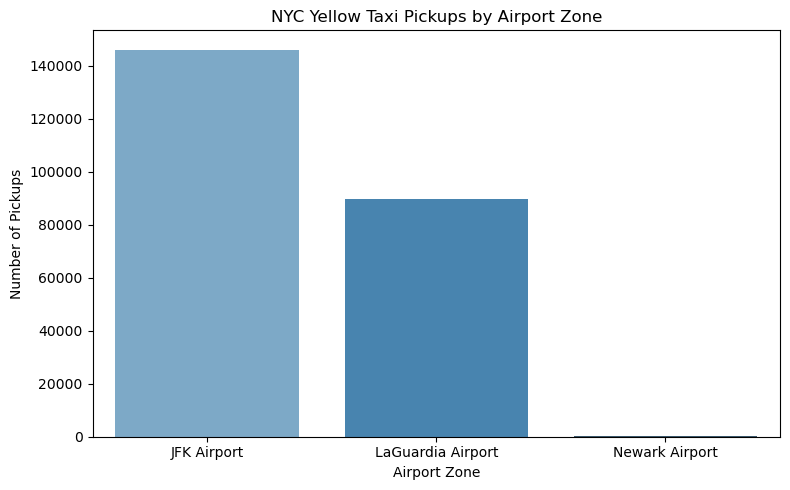

In [38]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=airport_zones,
    x="Zone",
    y="pickup_count",
    hue="Zone",
    palette="Blues_d",
    legend=False
)

plt.title("NYC Yellow Taxi Pickups by Airport Zone")
plt.xlabel("Airport Zone")
plt.ylabel("Number of Pickups")
plt.tight_layout()
plt.show()

This bar chart compares the number of NYC Yellow Taxi pickups across the three airport zones identified in the dataset. Each bar represents an airport, and its height indicates the number of pickups. JFK Airport had the highest demand, with 146,137 pickups, followed by LaGuardia Airport with 89,658. Newark Airport recorded only 377 pickups, making its bar nearly invisible at the scale of the chart.

### 3. Relationship Between Trip Distance and Duration

In [39]:
regression_sample = correlation_data.sample(
    n=10000,
    random_state=42
)

regression_sample.shape

(10000, 3)

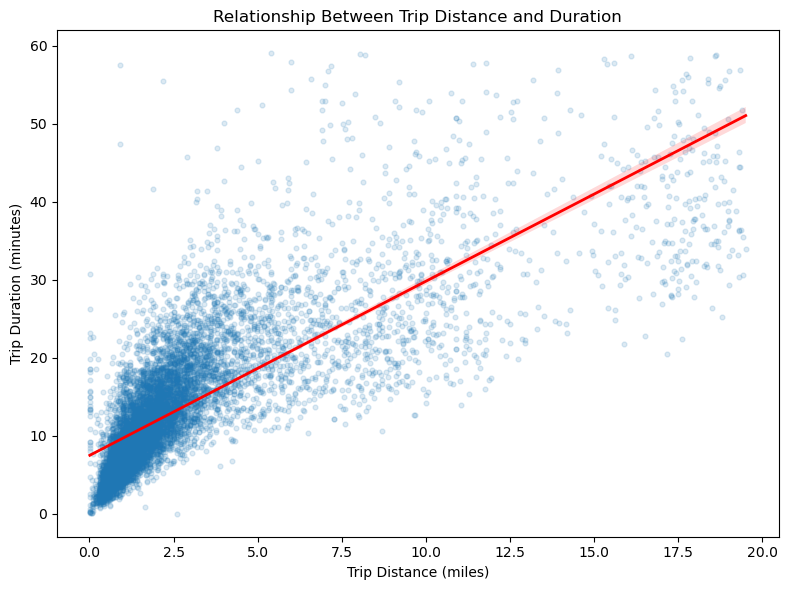

In [40]:
plt.figure(figsize=(8, 6))

sns.regplot(
    data=regression_sample,
    x="trip_distance",
    y="trip_duration_minutes",
    scatter_kws={
        "alpha": 0.15,
        "s": 12
    },
    line_kws={
        "color": "red",
        "linewidth": 2
    }
)

plt.title("Relationship Between Trip Distance and Duration")
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Trip Duration (minutes)")
plt.tight_layout()
plt.show()

Each blue point in this regression plot represents one NYC Yellow Taxi trip recorded in January 2025. The red line represents the overall relationship between trip distance and trip duration. Its upward slope shows that as trip distance increases, trip duration also tends to increase. The vertical dispersion indicates that trips of similar distances can have different durations because of factors such as traffic, route choice, time of day, and other travel conditions.

# Project Milestone 5: Tableau Dashboard Preparation

This section prepares a clean and analysis-ready dataset for the exploratory Tableau dashboard.

In [41]:
tableau_data = taxi_m3[
    [
        "tpep_pickup_datetime",
        "PULocationID",
        "payment_type",
        "trip_distance",
        "trip_duration_minutes",
        "total_amount"
    ]
].copy()

In [42]:
tableau_data.shape

(3475204, 6)

In [44]:
tableau_data = tableau_data.merge(
    zones[["LocationID", "Borough", "Zone"]],
    left_on="PULocationID",
    right_on="LocationID",
    how="left",
    validate="many_to_one"
)

tableau_data.shape

(3475204, 9)

In [45]:
tableau_data[["Borough", "Zone"]].isna().sum()

Borough    1380
Zone       8141
dtype: int64

In [46]:
missing_locations = (
    tableau_data.loc[
        tableau_data[["Borough", "Zone"]].isna().any(axis=1),
        ["PULocationID", "LocationID", "Borough", "Zone"]
    ]
    .value_counts(dropna=False)
    .reset_index(name="trip_count")
)

missing_locations

,PULocationID,LocationID,Borough,Zone,trip_count
0,264,264,Unknown,NaN,8141
1,265,265,NaN,Outside of NYC,1380


In [47]:
tableau_data["Borough"] = tableau_data["Borough"].fillna("Outside of NYC")
tableau_data["Zone"] = tableau_data["Zone"].fillna("Unknown")

tableau_data[["Borough", "Zone"]].isna().sum()

Borough    0
Zone       0
dtype: int64

In [48]:
payment_labels = {
    0: "Flex Fare",
    1: "Credit card",
    2: "Cash",
    3: "No charge",
    4: "Dispute",
    5: "Unknown"
}

tableau_data["payment_method"] = (
    tableau_data["payment_type"]
    .map(payment_labels)
)

tableau_data["payment_method"].value_counts(dropna=False)

payment_method
Credit card    2444377
Flex Fare       540149
Cash            390423
Dispute          76481
No charge        23773
Unknown              1
Name: count, dtype: int64

In [49]:
tableau_data["pickup_date"] = (
    tableau_data["tpep_pickup_datetime"].dt.floor("D")
)

tableau_data["pickup_day"] = (
    tableau_data["tpep_pickup_datetime"].dt.day_name()
)

tableau_data["pickup_hour"] = (
    tableau_data["tpep_pickup_datetime"].dt.hour
)

tableau_data[
    ["tpep_pickup_datetime", "pickup_date", "pickup_day", "pickup_hour"]
].head()

,tpep_pickup_datetime,pickup_date,pickup_day,pickup_hour
0,2025-01-01 00:18:38,2025-01-01,Wednesday,0
1,2025-01-01 00:32:40,2025-01-01,Wednesday,0
2,2025-01-01 00:44:04,2025-01-01,Wednesday,0
3,2025-01-01 00:14:27,2025-01-01,Wednesday,0
4,2025-01-01 00:21:34,2025-01-01,Wednesday,0


In [50]:
day_order = {
    "Monday": 1,
    "Tuesday": 2,
    "Wednesday": 3,
    "Thursday": 4,
    "Friday": 5,
    "Saturday": 6,
    "Sunday": 7
}

tableau_data["day_order"] = tableau_data["pickup_day"].map(day_order)
tableau_data["trip_count"] = 1

tableau_data[
    ["pickup_day", "day_order", "trip_count"]
].head()

,pickup_day,day_order,trip_count
0,Wednesday,3,1
1,Wednesday,3,1
2,Wednesday,3,1
3,Wednesday,3,1
4,Wednesday,3,1


In [52]:
tableau_final = tableau_data[
    [
        "tpep_pickup_datetime",
        "pickup_date",
        "pickup_day",
        "day_order",
        "pickup_hour",
        "PULocationID",
        "Borough",
        "Zone",
        "payment_method",
        "trip_distance",
        "trip_duration_minutes",
        "total_amount",
        "trip_count"
    ]
].copy()

tableau_final.shape

(3475204, 13)

In [53]:
quality_check = pd.DataFrame({
    "data_type": tableau_final.dtypes.astype(str),
    "missing_count": tableau_final.isna().sum()
})

quality_check

,data_type,missing_count
tpep_pickup_datetime,datetime64[us],0
pickup_date,datetime64[us],0
pickup_day,object,0
day_order,int64,0
pickup_hour,int32,0
PULocationID,int32,0
Borough,object,0
Zone,object,0
payment_method,category,0
trip_distance,float64,0


In [54]:
metric_ranges = (
    tableau_final[
        [
            "trip_distance",
            "trip_duration_minutes",
            "total_amount"
        ]
    ]
    .describe(percentiles=[0.01, 0.50, 0.99])
    .T
    .round(2)
)

metric_ranges

,count,mean,std,min,1%,50%,99%,max
trip_distance,3475204.0,5.86,564.60,0.00,0.00,1.67,19.50,276423.57
trip_duration_minutes,3475204.0,15.02,38.71,-51472.32,0.67,11.70,58.92,5626.32
total_amount,3475204.0,25.61,463.66,-901.00,-15.70,19.95,102.92,863380.37


In [55]:
metric_columns = [
    "trip_distance",
    "trip_duration_minutes",
    "total_amount"
]

positive_metrics = (
    tableau_final[metric_columns]
    .gt(0)
    .all(axis=1)
)

upper_limits = (
    tableau_final.loc[positive_metrics, metric_columns]
    .quantile(0.99)
)

valid_metric_mask = (
    positive_metrics
    & tableau_final[metric_columns]
        .le(upper_limits)
        .all(axis=1)
)

tableau_final["metric_quality"] = "Exclude from metric analysis"

tableau_final.loc[
    valid_metric_mask,
    "metric_quality"
] = "Valid for metric analysis"

print("Upper limits:")
display(upper_limits.round(2))

print("Record counts:")
tableau_final["metric_quality"].value_counts()

Upper limits:


trip_distance             19.53
trip_duration_minutes     59.07
total_amount             102.41
Name: 0.99, dtype: float64

Record counts:


metric_quality
Valid for metric analysis       3248053
Exclude from metric analysis     227151
Name: count, dtype: int64

### Treatment of Invalid and Extreme Metric Values

The original trip count was preserved because all records remain useful for analyzing taxi demand, pickup locations, and payment methods. However, some records contained nonpositive or extreme values for trip distance, trip duration, or total amount.

A record was classified as valid for metric analysis when all three measures were greater than zero and did not exceed their respective 99th-percentile limits: 19.53 miles, 59.07 minutes, and $102.41. This process retained 3,248,053 trips for metric-based analyses while preserving all 3,475,204 records in the final dataset.

In [56]:
print("Final shape:", tableau_final.shape)
print("Duplicated rows:", tableau_final.duplicated().sum())
print("Missing values:", tableau_final.isna().sum().sum())

tableau_final.head()

Final shape: (3475204, 14)
Duplicated rows: 0
Missing values: 0


,tpep_pickup_datetime,pickup_date,pickup_day,day_order,pickup_hour,PULocationID,Borough,Zone,payment_method,trip_distance,trip_duration_minutes,total_amount,trip_count,metric_quality
0,2025-01-01 00:18:38,2025-01-01,Wednesday,3,0,229,Manhattan,Sutton Place/Turtle Bay North,Credit card,1.60,8.350000,18.00,1,Valid for metric analysis
1,2025-01-01 00:32:40,2025-01-01,Wednesday,3,0,236,Manhattan,Upper East Side North,Credit card,0.50,2.550000,12.12,1,Valid for metric analysis
2,2025-01-01 00:44:04,2025-01-01,Wednesday,3,0,141,Manhattan,Lenox Hill West,Credit card,0.60,1.950000,12.10,1,Valid for metric analysis
3,2025-01-01 00:14:27,2025-01-01,Wednesday,3,0,244,Manhattan,Washington Heights South,Cash,0.52,5.566667,9.70,1,Valid for metric analysis
4,2025-01-01 00:21:34,2025-01-01,Wednesday,3,0,244,Manhattan,Washington Heights South,Cash,0.66,3.533333,8.30,1,Valid for metric analysis


In [57]:
output_file = "NYC_Yellow_Taxi_January_2025_Tableau.csv"

tableau_final.to_csv(
    output_file,
    index=False,
    date_format="%Y-%m-%d %H:%M:%S"
)

print("Export completed:")
print(output_file)

Export completed:
NYC_Yellow_Taxi_January_2025_Tableau.csv


In [58]:
from pathlib import Path

file_size_mb = Path(output_file).stat().st_size / (1024 ** 2)

print(f"File size: {file_size_mb:,.2f} MB")

pd.read_csv(
    output_file,
    nrows=5
)

File size: 488.85 MB


,tpep_pickup_datetime,pickup_date,pickup_day,day_order,pickup_hour,PULocationID,Borough,Zone,payment_method,trip_distance,trip_duration_minutes,total_amount,trip_count,metric_quality
0,2025-01-01 00:18:38,2025-01-01 00:00:00,Wednesday,3,0,229,Manhattan,Sutton Place/Turtle Bay North,Credit card,1.60,8.350000,18.00,1,Valid for metric analysis
1,2025-01-01 00:32:40,2025-01-01 00:00:00,Wednesday,3,0,236,Manhattan,Upper East Side North,Credit card,0.50,2.550000,12.12,1,Valid for metric analysis
2,2025-01-01 00:44:04,2025-01-01 00:00:00,Wednesday,3,0,141,Manhattan,Lenox Hill West,Credit card,0.60,1.950000,12.10,1,Valid for metric analysis
3,2025-01-01 00:14:27,2025-01-01 00:00:00,Wednesday,3,0,244,Manhattan,Washington Heights South,Cash,0.52,5.566667,9.70,1,Valid for metric analysis
4,2025-01-01 00:21:34,2025-01-01 00:00:00,Wednesday,3,0,244,Manhattan,Washington Heights South,Cash,0.66,3.533333,8.30,1,Valid for metric analysis
